# Challenge 3 — Evaluación final, inferencia y predicciones por lotes (Wine)

Reproduce los notebooks 5 y 6 del ejemplo de Breast Cancer:

1. carga el campeón guardado en el notebook 2;
2. **abre `test` por primera vez** y evalúa únicamente al campeón;
3. implementa una función de inferencia reutilizable con validación del esquema;
4. genera predicciones por lotes.

> Este notebook solo consume archivos (`data/processed/test.csv`, `artifacts/*`): no depende de variables en memoria de los notebooks anteriores.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, learning_curve


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_RAW = PROJECT_DIR / "data" / "raw"
DATA_PROCESSED = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"
for directory in (DATA_RAW, DATA_PROCESSED, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


## 1. Carga del campeón y del contrato

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

feature_columns = contract["features"]
class_names = contract["target_names"]
print("Campeón:", training_metadata["champion"], "| parámetros:", training_metadata["best_params"])

test_df = pd.read_csv(DATA_PROCESSED / "test.csv")
X_test = test_df[feature_columns]
y_test = test_df[contract["target"]]
print("Test:", test_df.shape)

Campeón: logistic_regression | parámetros: {'classifier__C': 10}
Test: (36, 14)


## 2. Evaluación final sobre `test` (una sola vez)

In [4]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

metrics = {
    "model": training_metadata["champion"],
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(y_test, y_pred, average="macro"),
    "recall_macro": recall_score(y_test, y_pred, average="macro"),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
    "roc_auc_ovr": roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"),
}
display(pd.Series(metrics))
print(classification_report(y_test, y_pred, target_names=class_names))

model              logistic_regression
accuracy                      0.972222
precision_macro               0.977778
recall_macro                  0.966667
f1_macro                      0.970962
roc_auc_ovr                        1.0
dtype: object

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



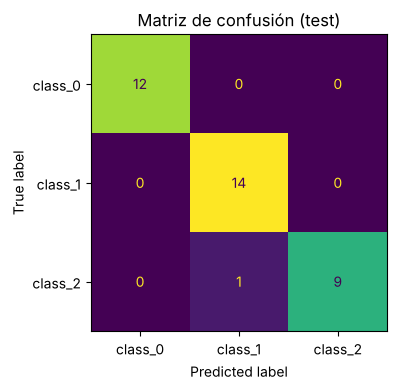

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, ax=ax, colorbar=False
)
ax.set_title("Matriz de confusión (test)")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "test_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. Curva de aprendizaje usando solo entrenamiento

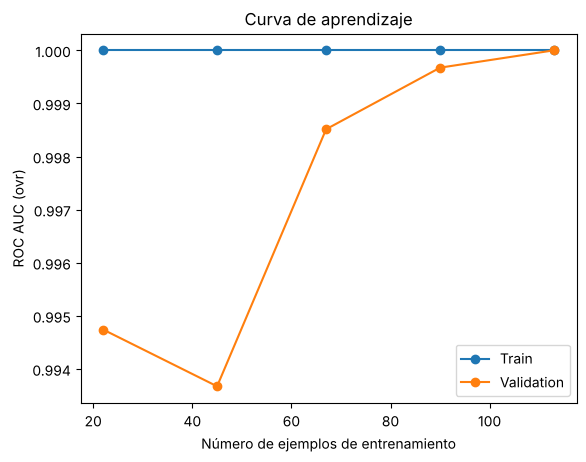

In [6]:
train_df = pd.read_csv(DATA_PROCESSED / "train.csv")
X_train = train_df[feature_columns]
y_train = train_df[contract["target"]]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

sizes, train_scores, validation_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc_ovr",
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    n_jobs=-1,
)

plt.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train")
plt.plot(sizes, validation_scores.mean(axis=1), marker="o", label="Validation")
plt.xlabel("Número de ejemplos de entrenamiento")
plt.ylabel("ROC AUC (ovr)")
plt.title("Curva de aprendizaje")
plt.legend()
plt.savefig(REPORTS_DIR / "learning_curve.png", dpi=120, bbox_inches="tight")
plt.show()

In [7]:
serializable_metrics = {
    key: (float(value) if key != "model" else value)
    for key, value in metrics.items()
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(serializable_metrics, indent=2), encoding="utf-8"
)
print("Reporte final guardado. El test no debe reutilizarse para ajustar el modelo.")

Reporte final guardado. El test no debe reutilizarse para ajustar el modelo.


## 4. Inferencia

Un modelo desplegable debe recibir observaciones con el **esquema original** y aplicar internamente las mismas transformaciones del entrenamiento. El artefacto `champion_model.joblib` ya contiene imputación, estandarización (si el campeón la necesita) y clasificador.

In [8]:
def validate_input(records: pd.DataFrame) -> pd.DataFrame:
    missing = sorted(set(feature_columns) - set(records.columns))
    extra = sorted(set(records.columns) - set(feature_columns))
    if missing:
        raise ValueError(f"Faltan variables requeridas: {missing}")
    if extra:
        print(f"Advertencia: se ignorarán columnas adicionales: {extra}")
    # Reordena las columnas según el contrato
    return records[feature_columns]


def predict(records: pd.DataFrame) -> pd.DataFrame:
    X = validate_input(records.copy())
    labels = model.predict(X)
    probabilities = model.predict_proba(X)

    result = pd.DataFrame({
        "prediction": labels,
        "predicted_class": [class_names[label] for label in labels],
    }, index=records.index)
    for k, name in enumerate(class_names):
        result[f"probability_{name}"] = probabilities[:, k]
    return result

### Comprobaciones del contrato de inferencia

In [9]:
sample = pd.read_csv(DATA_PROCESSED / "train.csv").drop(columns=contract["target"]).head(5)

# 1) Columnas desordenadas: debe dar exactamente las mismas predicciones
shuffled = sample[sample.columns[::-1]]
assert predict(shuffled)["prediction"].tolist() == predict(sample)["prediction"].tolist()
print("✓ Columnas desordenadas: mismas predicciones.")

# 2) Columna adicional: se ignora con una advertencia
_ = predict(sample.assign(columna_extra=1))
print("✓ Columna adicional ignorada.")

# 3) Columna faltante: debe fallar con un mensaje claro
try:
    predict(sample.drop(columns=["alcohol"]))
except ValueError as error:
    print("✓ Columna faltante detectada:", error)

# 4) Consistencia con el modelo: la función usa el mismo pipeline que la evaluación
assert predict(X_test)["prediction"].tolist() == y_pred.tolist()
print("✓ predict() reproduce las predicciones de la evaluación.")

✓ Columnas desordenadas: mismas predicciones.
Advertencia: se ignorarán columnas adicionales: ['columna_extra']
✓ Columna adicional ignorada.
✓ Columna faltante detectada: Faltan variables requeridas: ['alcohol']
✓ predict() reproduce las predicciones de la evaluación.


## 5. Predicción por lotes

In [10]:
# En producción este archivo representaría observaciones nuevas, no el test set.
sample.to_csv(DATA_PROCESSED / "inference_sample.csv", index=False)

batch = pd.read_csv(DATA_PROCESSED / "inference_sample.csv")
predictions = predict(batch)
predictions

,prediction,predicted_class,probability_class_0,probability_class_1,probability_class_2
0,0,class_0,0.999508,0.000423,0.000069
1,0,class_0,0.999708,0.000278,0.000014
2,0,class_0,0.999980,0.000011,0.000009
3,0,class_0,0.999977,0.000019,0.000004
4,2,class_2,0.000080,0.000014,0.999906


In [11]:
predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print("Predicciones guardadas en", (REPORTS_DIR / "batch_predictions.csv").relative_to(PROJECT_DIR))

# Las probabilidades de cada observación deben sumar 1
prob_cols = [c for c in predictions.columns if c.startswith("probability_")]
assert (predictions[prob_cols].sum(axis=1).sub(1).abs() < 1e-9).all()

Predicciones guardadas en reports/batch_predictions.csv


## Conclusiones

- **Rendimiento en `test`** (36 vinos, campeón: regresión logística con `C=10`): accuracy 0.972, precisión macro 0.978, recall macro 0.967, F1 macro 0.971 y ROC AUC (ovr) 1.000. Se clasificaron bien 35 de 36 vinos.
- **El único error** fue un vino de `class_2` clasificado como `class_1` (recall de `class_2` = 0.90; precisión de `class_1` = 0.93). Con solo 36 ejemplos un error equivale a ≈2.8 puntos de accuracy, así que estas cifras tienen bastante incertidumbre.
- **Coherencia con la validación cruzada**: la accuracy de `test` (0.972) coincide con la de CV (0.972) y no hay señales de sobreajuste ni de fuga de datos. La curva de aprendizaje de la regresión logística muestra AUC de entrenamiento = 1.0 y un AUC de validación que sube hasta ≈1.0 al aumentar los datos; el eje vertical solo abarca 0.994–1.000, es decir, el modelo está prácticamente saturado.
- **Inferencia**: `predict()` valida el esquema, reordena columnas, ignora columnas extra con una advertencia, falla con un mensaje claro si falta alguna variable y reproduce exactamente las predicciones de la evaluación. El artefacto guardado incluye preprocesamiento y clasificador, por lo que no hay que reconstruir el escalado a mano.
- **Antes de producción** haría falta versionar el artefacto y las dependencias, añadir pruebas y monitorizar la distribución de las entradas y de las predicciones.